# Virtual Robot Navigation

## Project Objective
The goal of this project is to simulate a robot moving through a grid while avoiding obstacles and finding a route to a destination.

## How It Works
The environment is represented as a grid. The robot starts at one location and must reach a goal. Some cells contain obstacles that the robot cannot cross.

## Tools
- Python
- Google Colab
- Matplotlib

## Learning Goals
- Represent a simple environment using Python.
- Understand grid coordinates.
- Implement a pathfinding algorithm.
- Visualize and test a robot's route.

## Limitations
This is a software simulation, not a physical robot. The environment and obstacles are predefined.

In [1]:

# Our virtual robot's environment

grid = [
    "S....",
    ".##..",
    "...#.",
    ".#...",
    "....G"
]

# S = Start
# G = Goal
# # = Obstacle
# . = Empty space

print("Our robot's grid:\n")

for row in grid:
    print(" ".join(row))


Our robot's grid:

S . . . .
. # # . .
. . . # .
. # . . .
. . . . G


In [2]:

start = (0, 0)
goal = (4, 4)

print("Robot start position:", start)
print("Goal position:", goal)

print("Number of rows:", len(grid))
print("Number of columns:", len(grid[0]))


Robot start position: (0, 0)
Goal position: (4, 4)
Number of rows: 5
Number of columns: 5


In [3]:

# Define the robot's movement directions

directions = {
    "up": (-1, 0),
    "down": (1, 0),
    "left": (0, -1),
    "right": (0, 1)
}

# Test moving right from the starting position
current_position = start

move = directions["right"]

new_position = (
    current_position[0] + move[0],
    current_position[1] + move[1]
)

print("Starting position:", current_position)
print("After moving right:", new_position)


Starting position: (0, 0)
After moving right: (0, 1)


In [4]:

def can_move(position):
    row, col = position

    # Check that the position is inside the grid
    if row < 0 or row >= len(grid):
        return False

    if col < 0 or col >= len(grid[0]):
        return False

    # Check that the cell is not an obstacle
    if grid[row][col] == "#":
        return False

    return True


# Test three possible moves
print("Move right from start:", can_move((0, 1)))
print("Move down to obstacle:", can_move((1, 1)))
print("Move outside grid:", can_move((-1, 0)))


Move right from start: True
Move down to obstacle: False
Move outside grid: False


In [5]:

from collections import deque

# Start exploring from the robot's starting position
queue = deque([start])

# Remember where each position came from
previous = {start: None}

while queue:
    current = queue.popleft()

    # Stop when the goal is reached
    if current == goal:
        break

    # Try moving in all four directions
    for move in directions.values():
        next_position = (
            current[0] + move[0],
            current[1] + move[1]
        )

        if can_move(next_position) and next_position not in previous:
            previous[next_position] = current
            queue.append(next_position)

# Reconstruct the route from goal back to start
path = []

if goal in previous:
    current = goal

    while current is not None:
        path.append(current)
        current = previous[current]

    path.reverse()

    print("Route found!")
    print("Route:", path)
    print("Number of moves:", len(path) - 1)
else:
    print("No route to the goal was found.")


Route found!
Route: [(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (4, 1), (4, 2), (4, 3), (4, 4)]
Number of moves: 8


In [6]:

display_grid = [list(row) for row in grid]

for r, c in path:
    if (r, c) != start and (r, c) != goal:
        display_grid[r][c] = "*"

print("\n".join(" ".join(row) for row in display_grid))


S . . . .
* # # . .
* . . # .
* # . . .
* * * * G


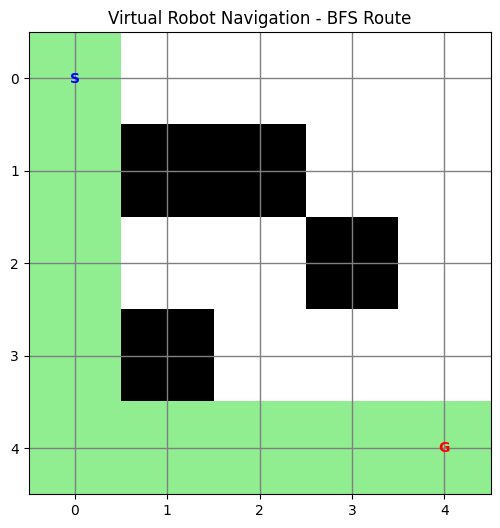

In [7]:

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# Convert the grid into numbers:
# 0 = open space, 1 = obstacle, 2 = route
visual_grid = []

for r in range(len(grid)):
    row_values = []
    for c in range(len(grid[0])):
        if grid[r][c] == "#":
            row_values.append(1)
        elif (r, c) in path:
            row_values.append(2)
        else:
            row_values.append(0)
    visual_grid.append(row_values)

plt.figure(figsize=(6, 6))
cmap = ListedColormap(["white", "black", "lightgreen"])
plt.imshow(visual_grid, cmap=cmap, vmin=0, vmax=2)

# Add grid lines and coordinate labels
plt.xticks(range(len(grid[0])))
plt.yticks(range(len(grid)))
plt.grid(True, color="gray", linewidth=1)
plt.title("Virtual Robot Navigation - BFS Route")

# Mark start and goal
plt.text(start[1], start[0], "S", ha="center", va="center",
         color="blue", fontweight="bold")
plt.text(goal[1], goal[0], "G", ha="center", va="center",
         color="red", fontweight="bold")

plt.show()


In [8]:

# Create a new environment with different obstacles
grid = [
    "S.#..",
    "..#..",
    ".....",
    ".##..",
    "...#G"
]

# Update start and goal
start = (0, 0)
goal = (4, 4)

# Display the new grid
for row in grid:
    print(" ".join(row))


S . # . .
. . # . .
. . . . .
. # # . .
. . . # G


In [9]:

from collections import deque

queue = deque([start])
previous = {start: None}

while queue:
    current = queue.popleft()

    if current == goal:
        break

    for move in directions.values():
        next_position = (
            current[0] + move[0],
            current[1] + move[1]
        )

        if can_move(next_position) and next_position not in previous:
            previous[next_position] = current
            queue.append(next_position)

path = []

if goal in previous:
    current = goal

    while current is not None:
        path.append(current)
        current = previous[current]

    path.reverse()

    print("Route found!")
    print("Route:", path)
    print("Number of moves:", len(path) - 1)
else:
    print("No route to the goal was found.")


Route found!
Route: [(0, 0), (1, 0), (2, 0), (2, 1), (2, 2), (2, 3), (3, 3), (3, 4), (4, 4)]
Number of moves: 8


In [10]:

display_grid = [list(row) for row in grid]

for r, c in path:
    if (r, c) != start and (r, c) != goal:
        display_grid[r][c] = "*"

print("New robot route:\n")
print("\n".join(" ".join(row) for row in display_grid))


New robot route:

S . # . .
* . # . .
* * * * .
. # # * *
. . . # G


In [11]:

if goal in previous:
    total_moves = len(path) - 1

    print("Route successfully completed!")
    print("Starting position:", start)
    print("Goal position:", goal)
    print("Total moves required:", total_moves)
    print("Cells in the route:", len(path))
else:
    print("The robot could not reach the goal.")


Route successfully completed!
Starting position: (0, 0)
Goal position: (4, 4)
Total moves required: 8
Cells in the route: 9


In [12]:

# Check the route length
print("Number of moves:", len(path) - 1)

# Check that every move is to an adjacent cell
valid_steps = True

for i in range(len(path) - 1):
    r1, c1 = path[i]
    r2, c2 = path[i + 1]

    if abs(r1 - r2) + abs(c1 - c2) != 1:
        valid_steps = False

print("Are all moves valid?", valid_steps)
print("Does the route reach the goal?", path[-1] == goal)


Number of moves: 8
Are all moves valid? True
Does the route reach the goal? True


## Results and Conclusion

The Virtual Robot Navigation project demonstrates how a robot can navigate a grid-based environment while avoiding obstacles.

A Breadth-First Search (BFS) algorithm was implemented to find a route from the start position to the goal. The route was visualized using Python and Matplotlib.

### Key Results
- Successfully found a route through the initial environment.
- Tested the algorithm with a modified obstacle layout.
- Verified that each step in the route moves to an adjacent cell.
- The robot reached the goal in 8 moves in the modified environment.
- BFS finds a shortest route when every movement has equal cost.

### Tools Used
- Python
- Google Colab
- Matplotlib
- Breadth-First Search

### Limitations
This project is a software simulation. It does not model real-world sensor readings, robot physics, or movement uncertainty.

### Future Improvements
- Compare BFS with A* pathfinding.
- Add randomly generated obstacle layouts.
- Animate the robot moving along its route.
- Explore how the robot could use simulated sensor data.